In [2]:
!pip install pyod

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.4/417.4 kB 12.9 MB/s eta 0:00:00


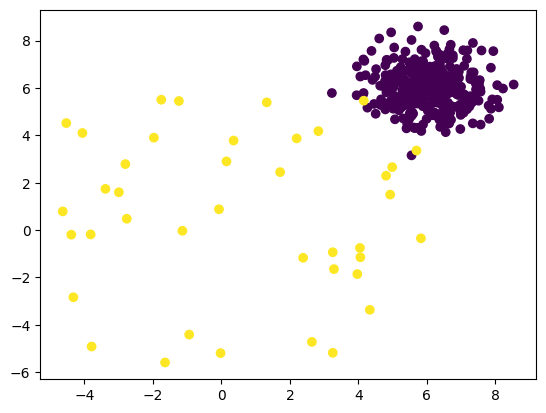


Confusion Matrix
 [[57 33]
 [ 0 10]]


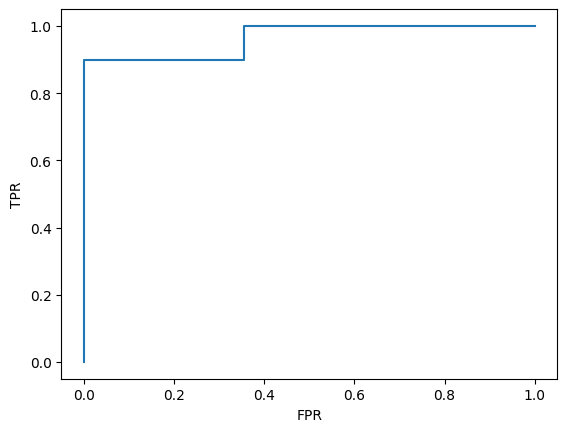

Balanced accuracy score: 0.8166666666666667


In [ ]:
# Ex. 1

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pyod.models.knn import KNN
from pyod.utils.data import generate_data
from sklearn.metrics import confusion_matrix, roc_curve, balanced_accuracy_score

X_train, X_test, Y_train, Y_test = generate_data(
    n_train = 400,
    n_test = 100,
    n_features = 2,
    contamination = 0.1,
    random_state = 42
)

df_train = pd.DataFrame(X_train)
df_train['y'] = Y_train
plt.scatter(df_train[0], df_train[1], c=df_train['y'])
plt.show()


# Ex. 2

m_knn = KNN(contamination=0.5)
m_knn.fit(X_train)

Y_train_pred = m_knn.labels_
Y_train_scores = m_knn.decision_scores_

Y_test_pred = m_knn.predict(X_test)
Y_test_scores = m_knn.decision_function(X_test)

Y_pred_pb = m_knn.predict_proba(X_test)[:, 1]

confusion_matrix(Y_test, Y_test_pred)
print("\nConfusion Matrix\n", confusion_matrix(Y_test, Y_test_pred))

# TP FN
# FP TN

fpr, tpr, thresholds = roc_curve(Y_test, Y_pred_pb)
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.plot(fpr, tpr)
plt.show()

print("Balanced accuracy score:", balanced_accuracy_score(Y_test, Y_test_pred))

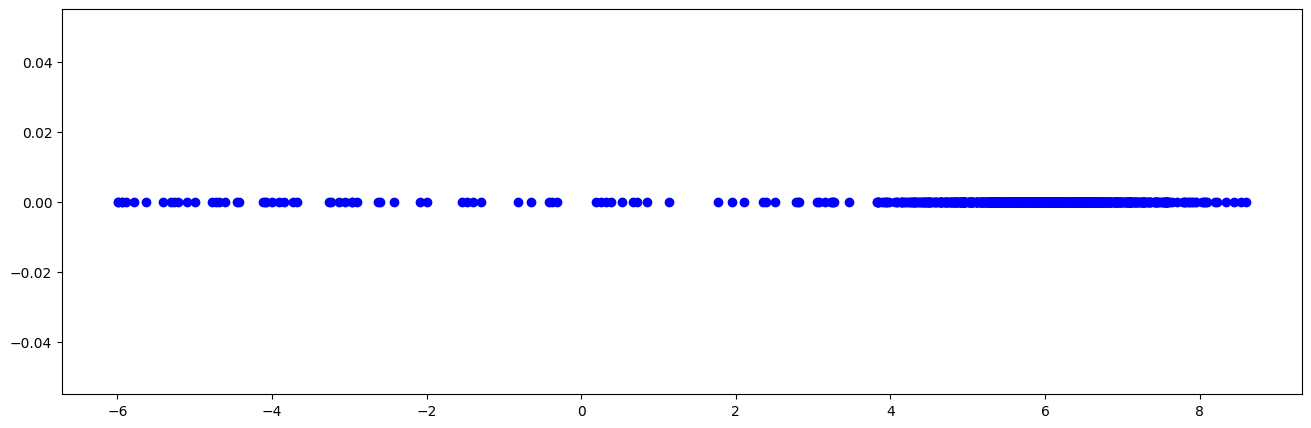

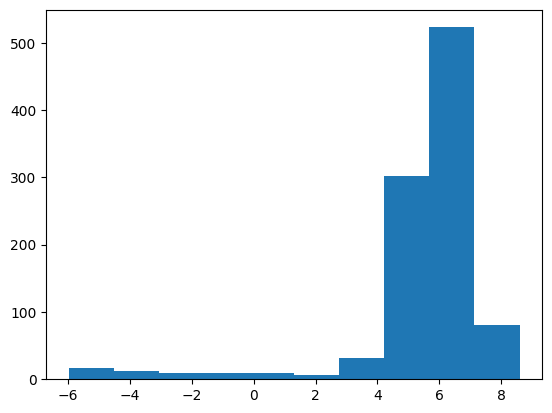

Anomaly Treshold: 7.062091655329504
Balanced accuracy score: 0.5


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:4109: FutureWarning: The behavior of DataFrame.std with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return std(axis=axis, dtype=dtype, out=out, ddof=ddof, **kwargs)


In [ ]:
# Ex. 3

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pyod.utils.data import generate_data
from sklearn.metrics import balanced_accuracy_score

X_train, Y_train = generate_data(
    train_only = True,
    n_train = 1000,
    n_features = 1,
    contamination = 0.1,
    random_state = 42
)

Y_train = np.zeros(len(X_train))
plt.figure(figsize=(16, 5))
plt.scatter(X_train, Y_train, c="blue")
plt.show()

df = pd.DataFrame(X_train)
plt.hist(df)
plt.show()

qnt = np.quantile(df, 0.9)
print("Anomaly Treshold:", qnt)

mhln_score = np.array((df - np.mean(df)) / np.std(df))
# print("\n", Z_score)

Y_pred = np.array(1 if x > qnt else 0 for x in np.abs(Z_score))
# print("\n", Y_pred)

print("Balanced accuracy score:", balanced_accuracy_score(X_train, Y_pred))


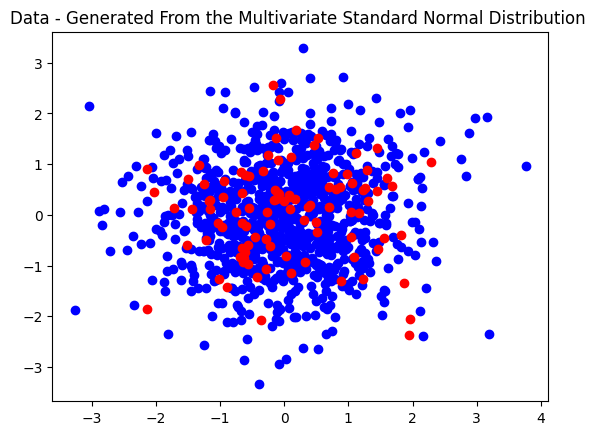

(900, 2)
(100, 2)
(1000, 2)


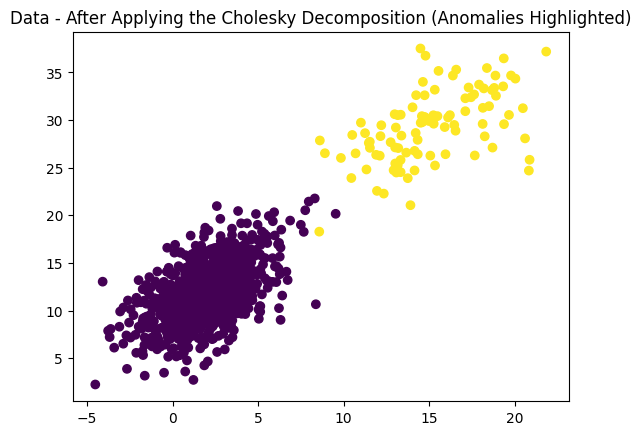

Anomaly Threshold: 3.8956697801264104
Balanced accuracy score: 0.9944444444444445


In [54]:
# Ex. 4

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pyod.utils.data import generate_data
from sklearn.metrics import balanced_accuracy_score

mu_std = np.array([0, 0])
cov_std = np.eye(2)

mu_ndata = np.array([2, 12])
cov_ndata = np.array([[4, 3],
                      [3, 9]])

mu_andata = np.array([15, 29])
cov_andata = np.array([[9, 6],
                      [6, 16]])

ndata = np.random.multivariate_normal(mu_std, cov_std, 900)
andata = np.random.multivariate_normal(mu_std, cov_std, 100)

plt.scatter(ndata[:, 0], ndata[:, 1], c="blue")
plt.scatter(andata[:, 0], andata[:, 1], c="red")
plt.title("Data - Generated From the Multivariate Standard Normal Distribution ")
plt.show()

L_ndata = np.linalg.cholesky(cov_ndata)
L_andata = np.linalg.cholesky(cov_andata)

Y_true_n = ndata @ L_ndata.T + mu_ndata
Y_true_an = andata @ L_andata.T + mu_andata

print(np.shape(Y_true_n))
print(np.shape(Y_true_an))

Y_true = np.concatenate((Y_true_n, Y_true_an), axis=0)
print(np.shape(Y_true))

df = pd.DataFrame(Y_true, columns=['x1', 'x2'])
labels = np.concatenate((np.zeros(900), np.ones(100)))
df['y'] = labels

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

plt.scatter(df['x1'], df['x2'], c=df['y'])
plt.title("Data - After Applying the Cholesky Decomposition (Anomalies Highlighted)")
plt.show()

X = df[['x1', 'x2']].values

diff = X - mu_ndata
inv_cov = np.linalg.inv(cov_ndata)

Z_score = np.sqrt(np.sum((diff @ inv_cov) * diff, axis=1))

qnt = np.quantile(Z_score, 0.9)
print("Anomaly Threshold:", qnt)

Y_pred = np.array([1 if x > qnt else 0 for x in Z_score])

print("Balanced accuracy score:", balanced_accuracy_score(df['y'], Y_pred))
